# Multi-Armed Bandits: Greedy, ε-Greedy, UCB1 and Thompson Sampling

**Robot Learning — Lecture 9 (Bandits & Exploration/Exploitation), Politecnico di Torino, A.Y. 2026-27**

This notebook reproduces the *"Regret in Practice: a Small Simulation"* slide. We compare four action-selection strategies on the same family of problems and measure how much reward each one loses while it learns.

**Problem setting.** A *K-armed Bernoulli bandit* is a slot machine with $K$ levers. Lever $a$ pays $r=1$ with probability $\mu_a$ and $r=0$ otherwise. The agent does not know the $\mu_a$. At every step it pulls **one** lever and observes the reward.

**What we measure.** The *total regret* after $t$ steps is the expected reward lost by not always pulling the best lever:

$$L_t = \sum_{\tau=1}^{t} \left(\mu^* - \mu_{a_\tau}\right), \qquad \mu^* = \max_a \mu_a .$$

**How we evaluate.** One *run* = one slot machine with freshly drawn $\mu_a \sim U[0.1, 0.9]$, played for $T$ steps by an agent that starts from scratch. We repeat this for `R` independent runs (different machines) and average the regret curves. A single run is very noisy: some machines are easy (the best arm stands out), others are hard (two arms are almost equal).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## Parameters

Change these and re-run the notebook. The defaults match the slide and take well under a minute on a laptop or on Colab. Check what changes for other values, e.g. `T = 10_000`.

In [2]:
K = 10          # number of arms (levers)
T = 100000     # steps per run
R = 200         # independent runs (different random bandits), simulated in parallel
EPS = 0.1       # exploration rate of epsilon-greedy
SEED = 4

## The environment

All `R` runs are simulated **in parallel** as numpy arrays: row `i` is run `i`. `mu[i, a]` is the true success probability of arm `a` in run `i`; the agents never look at it, it is used only to draw rewards and to compute regret.

In [3]:
def make_bandits(rng):
    mu = rng.uniform(0.1, 0.9, size=(R, K))     # true arm means, one bandit per row
    return mu

def pull(mu, a, rng):
    """Pull arm a[i] in every run i; return 0/1 rewards."""
    p = mu[np.arange(R), a]
    return (rng.random(R) < p).astype(float)

## Exploration strategies

Each agent keeps, for every run and arm, the number of pulls $N(a)$ and the number of successes $S(a)$. The empirical mean is $\hat{Q}(a) = S(a) / N(a)$.

| Strategy | Rule at step $t$ |
|---|---|
| **Greedy** | pull every arm once, then always $\arg\max_a \hat{Q}(a)$ |
| **ε-greedy** | like greedy, but with probability ε pull a uniformly random arm |
| **UCB1** (Auer et al., 2002) | pull every arm once, then $\arg\max_a \hat{Q}(a) + \sqrt{2 \ln t \,/\, N(a)}$ |
| **Thompson sampling** | prior $\mathrm{Beta}(1,1)$ per arm; sample $\theta_a \sim \mathrm{Beta}(1+S(a),\, 1+N(a)-S(a))$ and pull $\arg\max_a \theta_a$ |

UCB1 adds an *exploration bonus* that is large for arms pulled rarely and shrinks as $N(a)$ grows: it is *optimistic in the face of uncertainty*. Thompson sampling keeps a full posterior over each $\mu_a$ and picks each arm with the probability that it is the best one (*probability matching*).

In [4]:
def choose(alg, t, N, S, rng):
    idx = np.arange(R)
    if alg != "thompson" and t < K:            # initialisation: pull each arm once
        return np.full(R, t)
    if alg == "greedy":
        return np.argmax(S / N, axis=1)
    if alg == "eps-greedy":
        explore = rng.random(R) < EPS
        return np.where(explore, rng.integers(K, size=R), np.argmax(S / N, axis=1))
    if alg == "ucb1":
        return np.argmax(S / N + np.sqrt(2 * np.log(t + 1) / N), axis=1)
    if alg == "thompson":
        return np.argmax(rng.beta(1 + S, 1 + N - S), axis=1)
    raise ValueError(alg)


def run(alg, mu, rng):
    """Play T steps in all R runs; return per-step regret and whether the best arm was pulled."""
    idx = np.arange(R)
    N = np.zeros((R, K)); S = np.zeros((R, K))
    best_arm = mu.argmax(axis=1); best_mu = mu.max(axis=1)
    regret = np.zeros((T, R)); optimal = np.zeros((T, R))
    for t in range(T):
        a = choose(alg, t, N, S, rng)
        r = pull(mu, a, rng)
        N[idx, a] += 1; S[idx, a] += r
        regret[t] = best_mu - mu[idx, a]          # expected regret of this choice
        optimal[t] = (a == best_arm)
    return regret, optimal

## Run the experiment

Every algorithm plays **the same** `R` bandits (same `mu`), so the comparison is fair.

In [5]:
rng = np.random.default_rng(SEED)
mu = make_bandits(rng)

ALGS = ["greedy", "eps-greedy", "ucb1", "thompson"]
results = {}
for alg in ALGS:
    results[alg] = run(alg, mu, np.random.default_rng(SEED + 1))
    total = results[alg][0].sum(axis=0)      # total regret of each run
    print(f"{alg:>11}: mean total regret after T={T}: {total.mean():8.1f}  (std over runs {total.std():7.1f})")

     greedy: mean total regret after T=100000:   4930.4  (std over runs  8183.0)


 eps-greedy: mean total regret after T=100000:   3338.8  (std over runs   675.1)


       ucb1: mean total regret after T=100000:    815.3  (std over runs   220.2)


   thompson: mean total regret after T=100000:    111.1  (std over runs    57.2)


## Total regret over time

The x-axis is logarithmic: a regret that grows **linearly** in $t$ curves upward, a regret that grows **logarithmically** becomes a straight line.

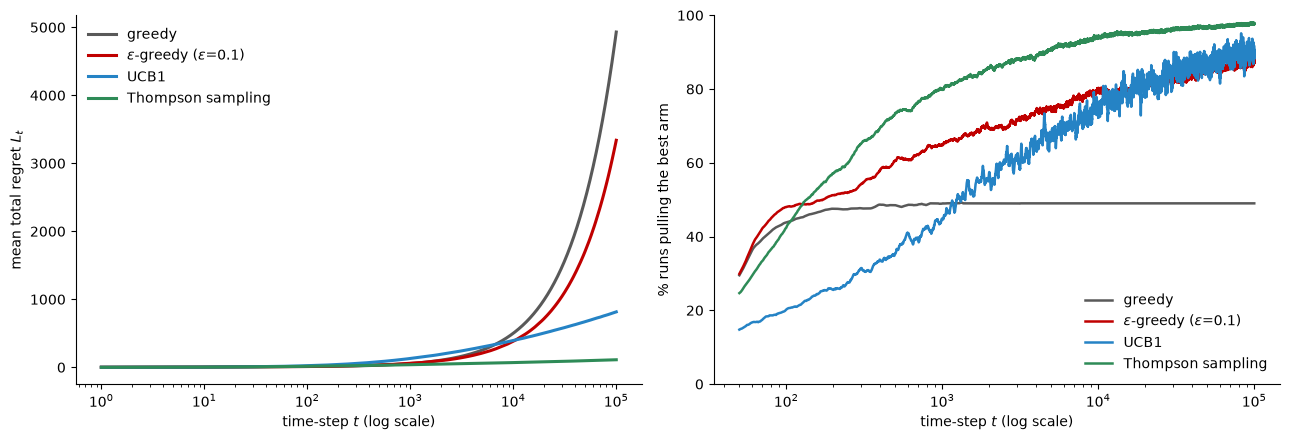

In [6]:
LABEL = {"greedy": "greedy", "eps-greedy": f"$\\epsilon$-greedy ($\\epsilon$={EPS})", "ucb1": "UCB1", "thompson": "Thompson sampling"}
COLOR = {"greedy": "#595959", "eps-greedy": "#C00000", "ucb1": "#2583C5", "thompson": "#2E8B57"}
steps = np.arange(1, T + 1)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for alg in ALGS:
    regret, optimal = results[alg]
    axs[0].plot(steps, regret.sum(axis=1).cumsum() / R, color=COLOR[alg], lw=2.2, label=LABEL[alg])
    share = optimal.mean(axis=1)
    smooth = np.convolve(share, np.ones(50) / 50, mode="valid")      # moving average over 50 steps
    axs[1].plot(steps[49:], 100 * smooth, color=COLOR[alg], lw=1.8, label=LABEL[alg])
axs[0].set(xscale="log", xlabel="time-step $t$ (log scale)", ylabel="mean total regret $L_t$")
axs[1].set(xscale="log", xlabel="time-step $t$ (log scale)", ylabel="% runs pulling the best arm", ylim=(0, 100))
for ax in axs:
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

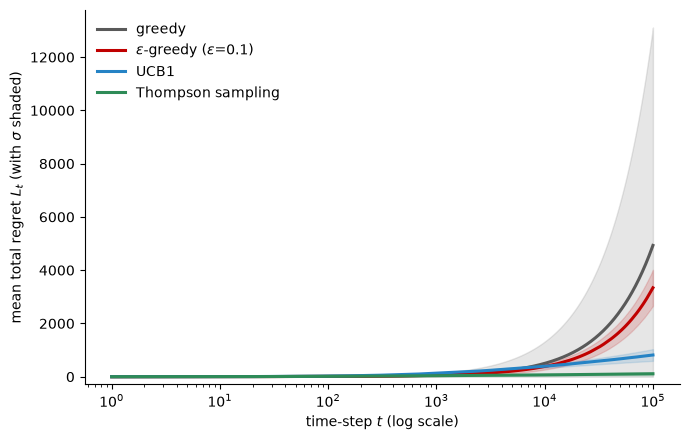

In [7]:
steps = np.arange(1, T + 1)
fig, ax = plt.subplots(figsize=(7, 4.5))

for alg in ALGS:
    regret, _ = results[alg]
    cum_regret_runs = regret.cumsum(axis=0)
    mean_regret = cum_regret_runs.mean(axis=1)
    std_regret = cum_regret_runs.std(axis=1)

    # Plot mean and shaded standard deviation matching your styling
    ax.plot(steps, mean_regret, color=COLOR[alg], lw=2.2, label=LABEL[alg])
    # regret is never negative: clip the lower edge of the band at 0
    ax.fill_between(steps, np.maximum(mean_regret - std_regret, 0), mean_regret + std_regret, color=COLOR[alg], alpha=0.15)

# Using a raw string r"" to avoid LaTeX backslash syntax warnings
ax.set(xscale="log", xlabel="time-step $t$ (log scale)", ylabel=r"mean total regret $L_t$ (with $\sigma$ shaded)")
ax.set_ylim(bottom=-0.02 * ax.get_ylim()[1])   # a small margin below 0, so that the Thompson curve does not sit on the axis
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## What to look for

- **Greedy** can lock onto a wrong arm after its first pulls and never try the others again. It happens only in some runs, but those runs keep losing reward at every step, so the *average* regret grows **linearly**.
- **ε-greedy** with a fixed ε never stops exploring. Even after it has found the best arm, a fraction ε of the pulls are random, so the regret also grows **linearly** (with a smaller slope than greedy at the start, but forever).
- **UCB1** explores a lot at the beginning (its bonus is large for every arm), so for the first few thousand steps it can lose *more* than ε-greedy. Then its regret grows only **logarithmically** and the curves cross: the Lai–Robbins lower bound says no algorithm can do better than $O(\log t)$. This is why the horizon matters when you compare algorithms.
- **Thompson sampling** is also logarithmic and is usually the best in practice here: its exploration is driven by the actual posterior uncertainty, while the UCB1 bonus is a conservative worst-case bound.

The right plot shows the same story from another angle: the share of runs that are pulling the best arm at step $t$.

## Exercises

1. **Tune ε.** Try `EPS = 0.01` and `EPS = 0.3`. Which one is better early on, and which one at large $t$? Can a fixed ε ever give logarithmic regret?
2. **Decaying ε.** Implement $\epsilon_t = \min(1, c/t)$ as a new strategy. How sensitive is it to the choice of $c$? (Compare with the Auer et al. figure in the slides.)
3. **Harder problems.** Draw the arm means from $U[0.45, 0.55]$ instead of $U[0.1, 0.9]$. What happens to the gaps $\Delta_a = \mu^* - \mu_a$, and to the regret of each algorithm?
4. **UCB exploration constant.** Replace $\sqrt{2\ln t / N}$ with $c\sqrt{\ln t / N}$ and try a few values of $c$. Why does a smaller $c$ often help in practice, and what does it cost in theory?
5. **Optimistic initialisation.** Run *greedy* with $S(a)=1, N(a)=1$ for every arm at the start (an optimistic prior). Does it still get stuck?
